# What explains COVID-19 deaths per million across countries?

**Author:** Tanisha · Data: Our World in Data COVID-19 dataset (2020-01-01 to 2024-08-14)

Questions:
1. How did global cases and deaths evolve over the whole pandemic?
2. Which country characteristics go with higher deaths per million?
3. Do those relationships hold up once other factors are controlled for?

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from src import clean, features
from src.modeling import PREDICTORS, LABELS, fit_model

pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Load and clean

In [2]:
raw = clean.load_raw("../data/raw/owid-covid-data.csv")
df = clean.clean(raw)
print(f"raw rows: {len(raw):,}  ->  clean rows: {len(df):,}")
print(f"countries: {df['iso_code'].nunique()}  |  {df['date'].min().date()} to {df['date'].max().date()}")

raw rows: 429,435  ->  clean rows: 401,502
countries: 243  |  2020-01-01 to 2024-08-14


The 12 aggregate rows OWID adds (World, continents, income groups) are removed so they are not counted as countries. The cleaning functions are covered by unit tests in `tests/`.

## 2. Global timeline

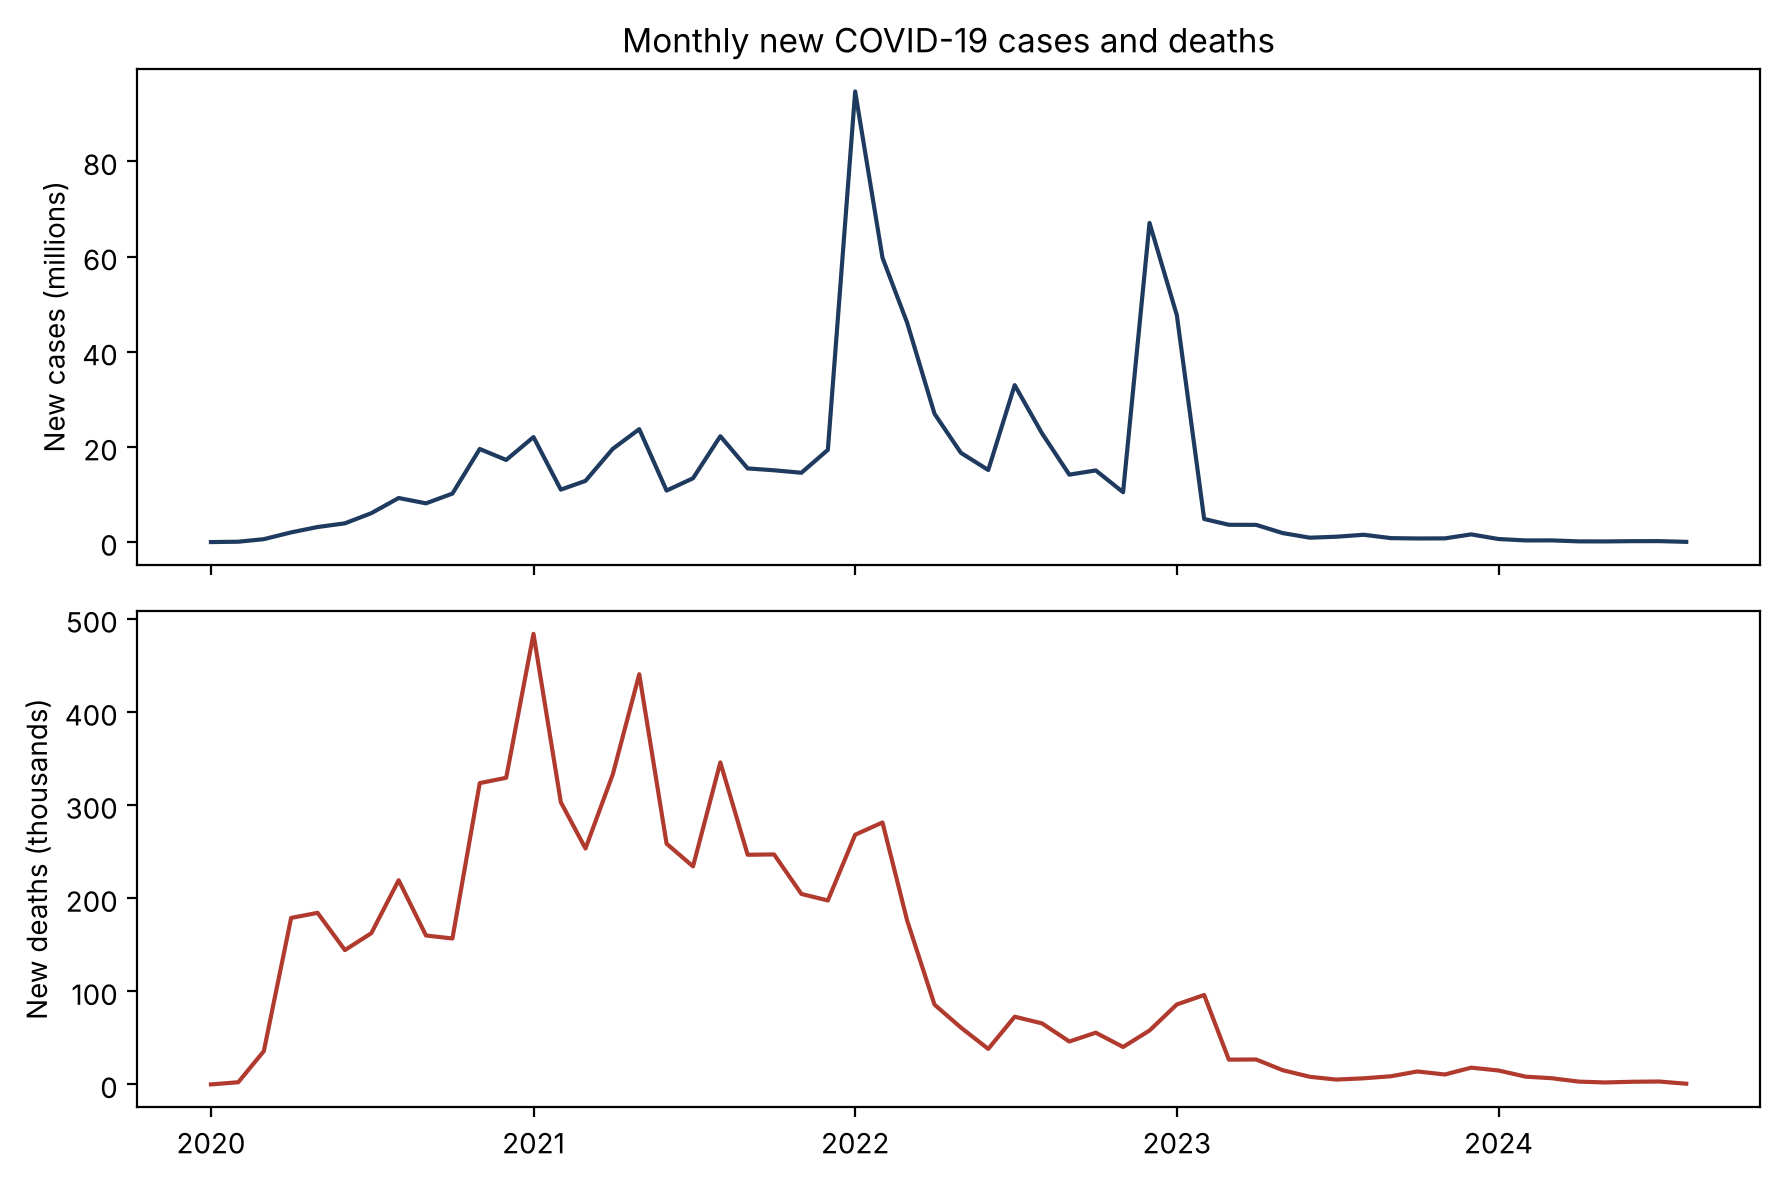

Cases peaked in January 2022; deaths peaked in January 2021


In [3]:
monthly = features.monthly_global(df)
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(monthly["month"], monthly["new_cases"] / 1e6, color="#1f3a5f")
axes[0].set_ylabel("New cases (millions)")
axes[1].plot(monthly["month"], monthly["new_deaths"] / 1e3, color="#b03a2e")
axes[1].set_ylabel("New deaths (thousands)")
axes[0].set_title("Monthly new COVID-19 cases and deaths")
plt.tight_layout(); plt.show()

peak_c = monthly.loc[monthly["new_cases"].idxmax()]
peak_d = monthly.loc[monthly["new_deaths"].idxmax()]
print(f"Cases peaked in {peak_c['month']:%B %Y}; deaths peaked in {peak_d['month']:%B %Y}")

Cases peaked in January 2022 but deaths peaked a full year earlier, in January 2021. Cases per month were far higher in the later waves while deaths per month were lower. Reporting and testing changed a lot over the period, so case counts are not directly comparable across waves.

## 3. Country-level table

In [4]:
summary = features.country_summary(df)
sample = features.analysis_sample(summary)
print(f"{len(summary)} countries -> {len(sample)} with population >= 1M and reported deaths")
sample[["location", "continent", "median_age", "gdp_per_capita", "deaths_per_million"]].sort_values(
    "deaths_per_million", ascending=False).head(10)

243 countries -> 156 with population >= 1M and reported deaths


,location,continent,median_age,gdp_per_capita,deaths_per_million
172,Peru,South America,29.10,"12,236.71","6,489.80"
20,Bulgaria,Europe,44.70,"18,563.31","5,706.32"
23,Bosnia and Herzegovina,Europe,42.50,"11,713.90","5,069.38"
94,Hungary,Europe,43.40,"26,777.56","4,921.39"
136,North Macedonia,Europe,39.10,"13,111.21","4,765.94"
204,Slovenia,Europe,44.50,"31,400.84","4,756.48"
92,Croatia,Europe,44.00,"22,669.80","4,652.68"
74,Georgia,Asia,38.70,"9,745.08","4,580.19"
52,Czechia,Europe,43.30,"32,605.91","4,146.09"
126,Latvia,Europe,43.90,"25,063.85","4,039.11"


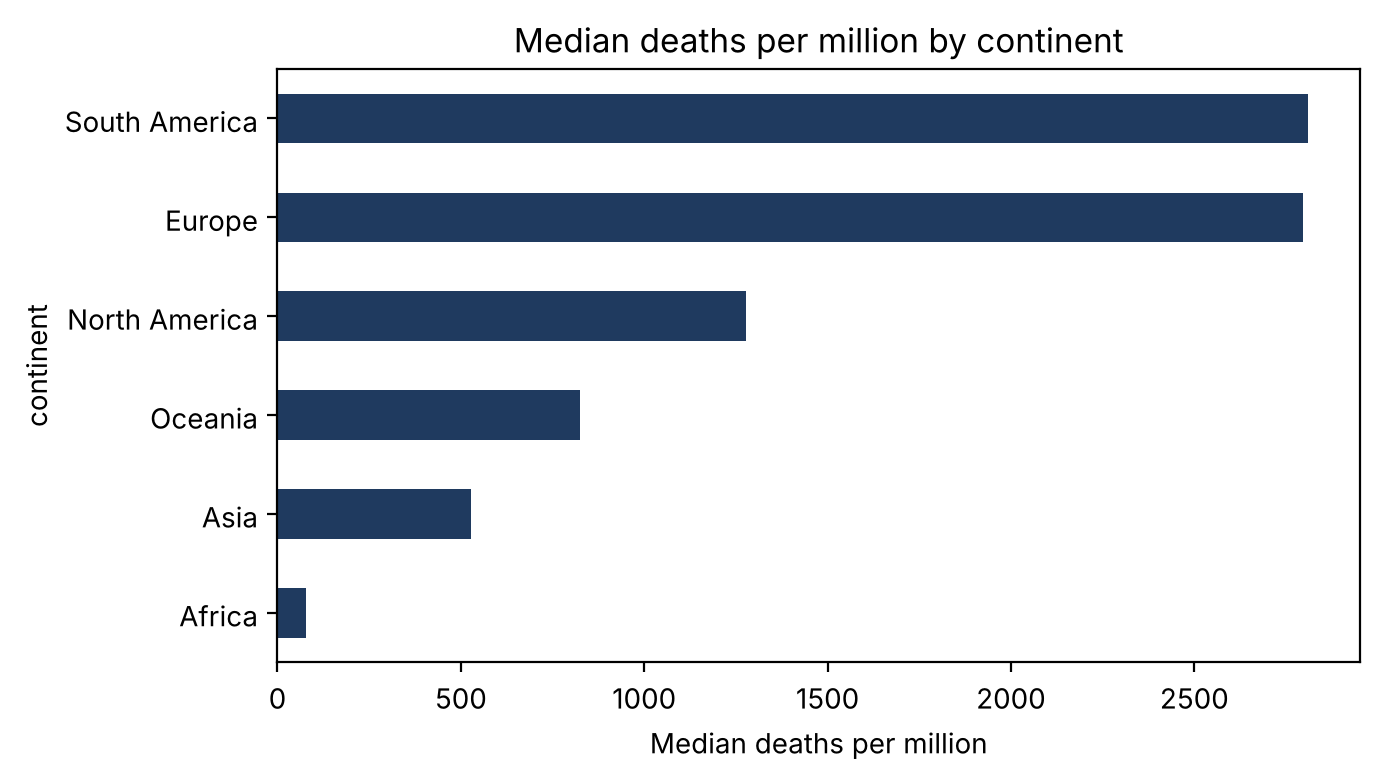

In [5]:
med = sample.groupby("continent")["deaths_per_million"].median().sort_values()
med.plot.barh(color="#1f3a5f", figsize=(7, 4), title="Median deaths per million by continent")
plt.xlabel("Median deaths per million"); plt.tight_layout(); plt.show()

## 4. Which factors go with deaths per million?

In [6]:
corr = (sample[PREDICTORS + ["deaths_per_million"]]
        .corr(method="spearman")["deaths_per_million"].drop("deaths_per_million")
        .rename(index=LABELS).sort_values(ascending=False))
corr.to_frame("Spearman correlation")

,Spearman correlation
Median age,0.80
GDP per capita (log),0.68
"Hospital beds per 1,000",0.62
Peak fully vaccinated %,0.39
Diabetes prevalence,0.23
Mean stringency index,0.15


Spearman correlation is used because deaths per million is heavily skewed. Median age has the strongest rank correlation with deaths per million (0.80), followed by GDP per capita (0.68) and hospital beds (0.62).

## 5. Regression with all factors together

In [7]:
model, n = fit_model(sample)
print(f"n = {n} countries, R-squared = {model.rsquared:.3f}, adjusted R-squared = {model.rsquared_adj:.3f}")
table = pd.DataFrame({"effect per 1 SD": model.params, "p-value": model.pvalues}).drop("const")
table.index = [LABELS[i] for i in table.index]
table.sort_values("effect per 1 SD", ascending=False)

n = 130 countries, R-squared = 0.654, adjusted R-squared = 0.637


,effect per 1 SD,p-value
Median age,0.44,0.00
GDP per capita (log),0.24,0.00
Mean stringency index,0.16,0.00
Diabetes prevalence,-0.03,0.51
"Hospital beds per 1,000",-0.05,0.39
Peak fully vaccinated %,-0.09,0.11


The model explains about 65% of the variation in log deaths per million across 130 countries.

- **Median age** has the largest effect (+0.44 per standard deviation, p < 0.001).
- **GDP per capita** is also positive (+0.24, p = 0.004).
- **Mean stringency** is positive too (+0.16, p < 0.001).
- **Hospital beds, diabetes prevalence and peak vaccination** are not significant at the 5% level once the others are included.

Hospital beds correlate with deaths on their own (0.62) but add nothing after controlling for age. That is a sign they mostly track the same thing as age and wealth.

## 6. Limitations

- **Reported deaths are not true deaths.** Richer countries tend to test and register deaths more completely, which probably explains part of the positive GDP effect. This analysis does not test that.
- **Stringency is not causal.** Countries with severe outbreaks adopted stricter measures, so the positive coefficient most likely reflects that, not that restrictions caused deaths.
- **Predictors overlap.** Median age, GDP and hospital beds are correlated, so individual coefficients are less stable than the overall fit.
- **Country averages hide variation** within countries and over time.
- **Peak vaccination** is the highest share fully vaccinated, not the timing, so it cannot show whether vaccines reduced deaths in specific waves.